# 03 - Experiments and results

**Goal.** Predict `_MICHD` (coronary heart disease or heart attack, BRFSS 2015) from the survey answers; metric = F1 of the positive class (8.8% positives).

**Protocol** (used for every number below):
* 20% stratified hold-out (`cv_final.holdout_split`, seed 2026, 65,627 rows), scored only for candidates already accepted in CV (14 times in total); never used to choose a hyperparameter.
* 5-fold stratified CV on the 262,508 dev rows (`cross_validation.build_k_indices`, seed 42). Preprocessing, target encoding, models and the threshold / positive rate are fitted **inside** each training fold.
* Acceptance rule for a change: mean CV F1 gain >= +0.001 **and** better on >= 4/5 folds.

The long runs (GBM, MLP, ensembles: hours of CPU) are **not** rerun here. Their numbers are read from `experiments/results/*.csv`, transcribed from the experiment logs (column `source`). Only the linear baselines run live, on a subsample.

In [1]:
import sys, time
sys.path.insert(0, "..")
import numpy as np
import matplotlib.pyplot as plt

import cross_validation as cv
from cv_final import holdout_split, f1_top_rate
from implementations import least_squares
from preprocessing import load_data_cached, load_feature_names, clean_data
from experiments import plots

T0 = time.time()

## 1. Linear baselines from `implementations.py` (live, subsample)

30,000 random dev rows (hold-out rows excluded), 3-fold CV with `cross_validation.cross_validate`: default pipeline (`preprocessing.DEFAULT_CONFIG`, fitted per training fold), threshold chosen on the training-fold scores. Small sample = larger fold-to-fold noise than the full-data numbers.

In [2]:
x, _, y, _, _ = load_data_cached("../data/dataset")
names = load_feature_names("../data/dataset")
dev, hold = holdout_split(y)
sub = np.sort(np.random.default_rng(0).choice(dev, 30000, replace=False))
xc, xc_names = clean_data(x[sub], names)
ys = y[sub]
del x

k_ind = cv.build_k_indices(ys, 3, seed=42)
folds = cv.prepare_folds(ys, xc, xc_names, k_ind, {})  # fitted on the training folds only


def train_ls(y_tr, tx, cfg):
    return least_squares(np.asarray(y_tr, float), tx)[0]


models = {
    "least squares": (train_ls, cv.linear_scores),
    "ridge (lambda 1e-4)": (cv.train_ridge, cv.linear_scores),
    "reg. logistic GD (1e-4, 0.5, 1000 it.)": (cv.train_reg_logistic, cv.logistic_scores),
}
print("%d rows, %.1f%% positive, %d features" % (len(ys), 100 * np.mean(ys == 1), folds[0][0].shape[1]))
for name, (train_fn, score_fn) in models.items():
    r = cv.cross_validate(ys, xc, xc_names, k_ind, {}, train_fn, score_fn, folds=folds)
    print("%-40s F1 %.4f +/- %.4f   (train F1 %.4f)" % (name, r["f1_mean"], r["f1_std"], r["f1_train_mean"]))
print("elapsed %.0fs" % (time.time() - T0))

30000 rows, 9.0% positive, 141 features
least squares                            F1 0.4304 +/- 0.0042   (train F1 0.4442)
ridge (lambda 1e-4)                      F1 0.4288 +/- 0.0065   (train F1 0.4440)


reg. logistic GD (1e-4, 0.5, 1000 it.)   F1 0.4330 +/- 0.0126   (train F1 0.4576)
elapsed 4s


**Full-data numbers** (5-fold dev CV, from the logs). Two metrics appear: threshold chosen on the training folds (selection phase) and "nested positive rate" (the share predicted +1 is chosen on the other 4 folds; used for the leakage ablation). The "top 14%" rows use the same rule as the final model (Table I of the report).

In [3]:
plots.show_table("baselines_full", ["model", "features", "cv_f1_mean", "cv_f1_std", "holdout_f1", "metric"])

model                                                        features                       cv_f1_mean  cv_f1_std  holdout_f1  metric                                           
Ridge regression (lambda 1e-4)                               v1 pipeline                    0.4133                             5-fold dev CV, threshold chosen on training folds
Linear SVM (Pegasos)                                         v1 pipeline                    0.4253                             5-fold dev CV, threshold chosen on training folds
Reg. logistic GD (lambda 1e-4 gamma 0.5 1000 it.)            v1 pipeline                    0.4281      0.0042     0.4281      5-fold dev CV, threshold chosen on training folds
Reg. logistic GD (lambda 1e-4 gamma 0.5 1000 it.)            v2 pipeline (10 interactions)  0.4301      0.0044     0.4277      5-fold dev CV, threshold chosen on training folds
Reg. logistic Newton (age x all + top-15 pairs + NaN flags)  v1 pipeline + interactions     0.4311      0.0040     

## 2. Model comparison

Same dev folds for all; GBM = numpy gradient-boosted trees (`gbm.py`, depth 5, `_STATE` as smoothed target encoding), MLP = mean of 10 nets with 64 ReLU units (`mlp.py`), ensemble = mean of the two logits, top 14% predicted +1 (nested CV).

model                           cv_f1_mean  cv_f1_std  holdout_f1  source                                                                                      
Least squares / ridge / MSE GD  0.4216      0.0034                 report_baselines/run.log (v2 pipeline, top 14%)                                             
MSE SGD (not converged)         0.3853      0.0085                 report_baselines/run.log (v2 pipeline, top 14%)                                             
Logistic GD                     0.4302      0.0047                 report_baselines/run.log (v2 pipeline, top 14%)                                             
Reg. logistic GD                0.4300      0.0044     0.4277      report_baselines/run.log (v2 pipeline, top 14%); held-out: models/ITERATIONS.md, Iteration 2
MLP 1x64 (10 seeds)             0.4334      0.0026     0.4310      models/ITERATIONS.md, Iteration 2 - CLOSED                                                  
GBM d5 + _STATE target enc.     0.4354  

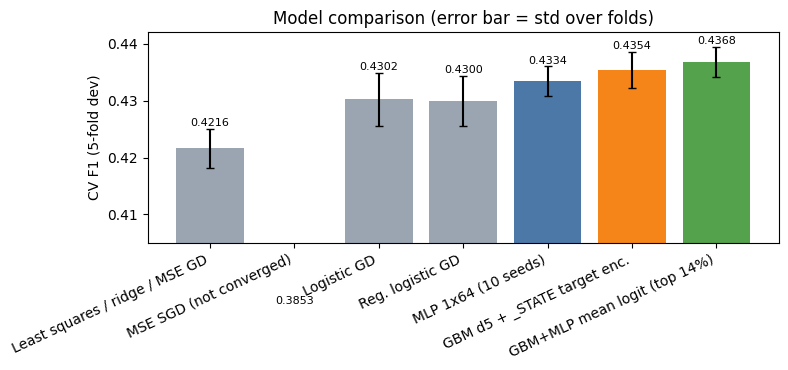

In [4]:
comp = plots.load_table("model_comparison")
plots.show_table("model_comparison", ["model", "cv_f1_mean", "cv_f1_std", "holdout_f1", "source"])
plots.plot_model_comparison(comp)
plt.show()

All non-linear models gain only +0.003 to +0.008 over the regularized logistic baseline; CV and hold-out agree within the hold-out noise (SE of F1 ~0.006).

## 3. Decision rule: share of rows predicted positive

Instead of a probability threshold, the final model predicts +1 for the top-scored share of rows (robust to score-scale shifts when the model is retrained on more rows). The solid curves are computed from the **saved out-of-fold scores** of the final GBM+MLP on the 262,508 dev rows (`f1_vs_rate.csv`); the dashed curve is a live illustration with the reg. logistic baseline on the 30k subsample.

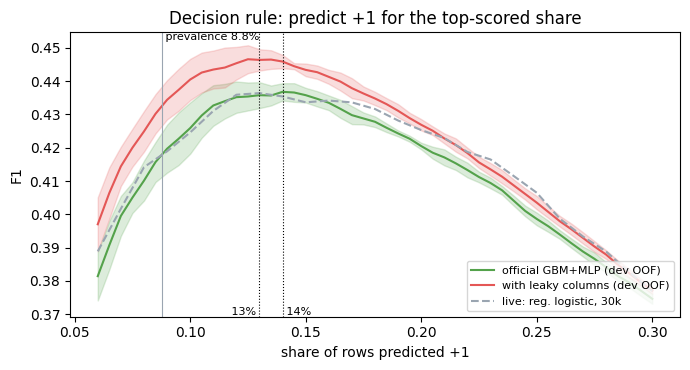

rate 0.10: official F1 0.4259 +/- 0.0077 | leaky F1 0.4405 +/- 0.0062
rate 0.13: official F1 0.4358 +/- 0.0039 | leaky F1 0.4464 +/- 0.0032
rate 0.14: official F1 0.4368 +/- 0.0026 | leaky F1 0.4459 +/- 0.0020
rate 0.18: official F1 0.4278 +/- 0.0016 | leaky F1 0.4348 +/- 0.0020


In [5]:
rates = np.round(np.arange(0.06, 0.3001, 0.01), 3)
f1_live = np.zeros((len(folds), len(rates)))
for k, (tx_tr, y_tr, tx_te, y_te, _) in enumerate(folds):
    w = cv.train_reg_logistic(y_tr, tx_tr, {})
    s = cv.logistic_scores(w, tx_te)
    f1_live[k] = [f1_top_rate(y_te, s, r)[2] for r in rates]

curve = plots.load_table("f1_vs_rate")
plots.plot_f1_vs_rate(curve, live=(rates, f1_live.mean(axis=0)))
plt.show()
for r in curve:
    if r["rate"] in (0.10, 0.13, 0.14, 0.18):
        print("rate %.2f: official F1 %.4f +/- %.4f | leaky F1 %.4f +/- %.4f"
              % (r["rate"], r["f1_clean_mean"], r["f1_clean_std"], r["f1_leaky_mean"], r["f1_leaky_std"]))

F1 is flat around its optimum: 14% (official) and 13% (with leaky columns) were chosen by CV; predicting more positives than the 8.8% prevalence trades precision (~0.35) for recall (~0.56).

## 4. Rejected alternatives

Each change was compared with the current reference on the same folds (mostly as a member of / replacement in the GBM+MLP ensemble). None was kept. The positive deltas were not robust: GBM without `_dk` flags (+0.0017) turned into -0.0004 at fixed rates 12.5-13.5%; the random forest (+0.0015, 2/3 folds) and k-NN (+0.0012, 3/5 folds) members were screened against a stricter +0.002 bar (iteration 8) and won too few folds; the others are below +0.001 or win < 4/5 folds. `[leaky]` rows were tuned on the leaky variant.

experiment                                                   variant  delta_f1  folds_won  metric                                
MLP on top-50 GBM columns (10 seeds)                         clean    -0.0006   0/5        ensemble top-14% F1 vs ref 0.4368     
Correlation pruning |r|>0.9 (MLP)                            clean    -0.0004              ensemble top-14% F1 vs ref 0.4368     
GBM + counts of chronic conditions (block A)                 clean    -0.0007   2/5        ensemble top-14% F1 vs ref 0.4368     
GBM + composites and NaN/dk counts (B+D)                     clean    -0.0009   0/5        ensemble top-14% F1 vs ref 0.4368     
GBM + crossed-cell target encodings                          clean    -0.0010   1/5        ensemble top-14% F1 vs ref 0.4368     
MLP + crossed-cell target encodings                          clean    -0.0006   1/5        ensemble top-14% F1 vs ref 0.4368     
GBM refit on 100% rows                                       clean    -0.0010   2/5       

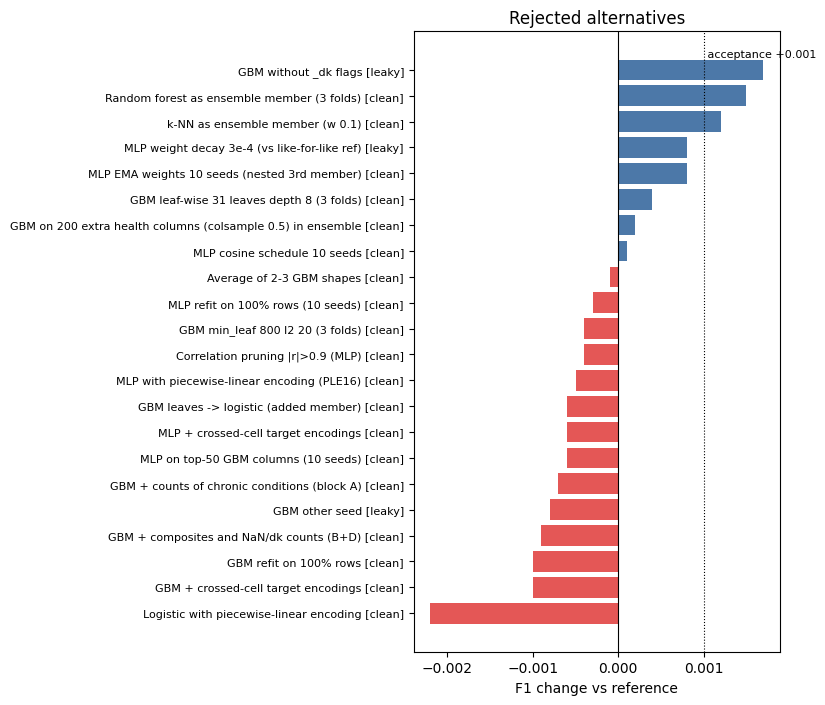

In [6]:
rej = plots.load_table("rejected")
plots.show_table("rejected", ["experiment", "variant", "delta_f1", "folds_won", "metric"])
plots.plot_rejected(rej)  # naive Bayes (-0.0162) left out of the plot for scale
plt.show()

## 5. Leakage ablation

Seven questions concern care after a heart attack or stroke: rehabilitation (`HAREHAB1`, `STREHAB1`, asked only after the event) and aspirin use and its reasons (`CVDASPRN`, `RDUCHART`, ...; weaker). They make every model better (+0.009 to +0.012 nested F1, 5/5 folds), but a screening model is meant for **undiagnosed** people, for whom these answers do not exist. The official model therefore excludes them; the leaky variant (`run.py --with_leakage`) is reported only to measure the leak. "clean+override" = clean model plus the hard rule "HAREHAB1 answered => +1".

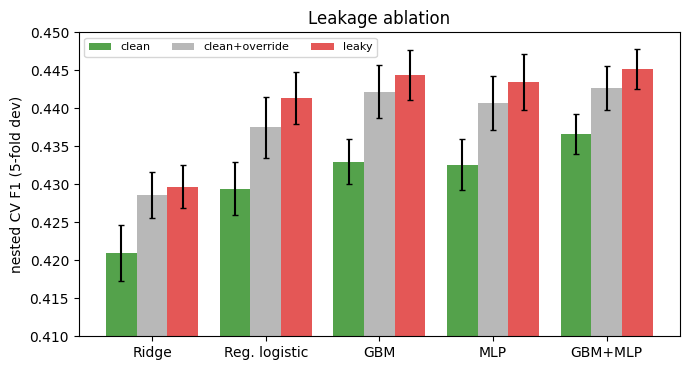

column    lr_clean_plus_col_nested  delta_vs_clean  won_vs_clean  delta_vs_leaky_all
HAREHAB1  0.4376                    0.0082          5/5           -0.0103           
STREHAB1  0.4293                    -0.0000         3/5           -0.0003           
CVDASPRN  0.4307                    0.0013          5/5           0.0000            
RDUCHART  0.4301                    0.0007          4/5           0.0000            
RDUCSTRK  0.4298                    0.0004          3/5           -0.0001           
RLIVPAIN  0.4298                    0.0004          3/5           0.0001            
ASPUNSAF  0.4302                    0.0008          5/5           -0.0004           


In [7]:
abl = plots.load_table("leakage_ablation")
plots.plot_leakage(abl)
plt.show()
plots.show_table("leaky_columns", ["column", "lr_clean_plus_col_nested", "delta_vs_clean", "won_vs_clean", "delta_vs_leaky_all"])

`HAREHAB1` carries most of the leak (adding only it to the clean logistic: +0.0082, 5/5 folds); the aspirin columns are redundant with each other.

## 6. Feature importance and simple rules

Permutation importance of the reference GBM: drop of AUC on the test rows of folds 0-2 when one column is shuffled.

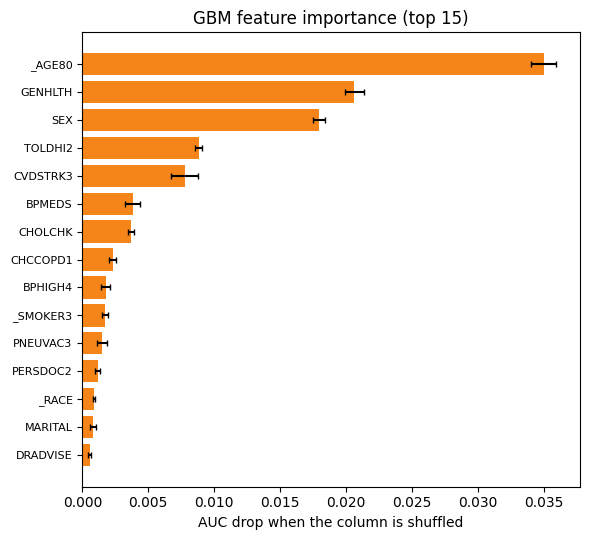

rule                                   support  precision  recall  lift
all rows                               1.000    0.088      1.000   1.00
age >= 65                              0.345    0.167      0.654   1.89
n_chronic >= 3                         0.314    0.201      0.717   2.28
n_chronic >= 5                         0.080    0.329      0.297   3.72
age >= 65 & n_chronic >= 3             0.178    0.240      0.483   2.72
age >= 65 & male & n_chronic >= 3      0.067    0.318      0.242   3.60
GENHLTH >= 4 (fair/poor)               0.184    0.229      0.478   2.60
age >= 65 & GENHLTH >= 4               0.080    0.321      0.290   3.64
stroke (CVDSTRK3 = yes)                0.040    0.374      0.171   4.24
male & age >= 55 & diabetes & high BP  0.035    0.325      0.129   3.68
n_cardiomet >= 4                       0.057    0.298      0.194   3.37
n_functional >= 3                      0.123    0.238      0.332   2.70
age >= 65 & n_functional >= 2          0.096    0.272      0.294

In [8]:
imp = plots.load_table("feature_importance")
plots.plot_importance(imp, top=15)
plt.show()
plots.show_table("rules", ["rule", "support", "precision", "recall", "lift"])

Age, general health, sex, high cholesterol and a previous stroke dominate. The rules (dev rows, no fitting) show the same picture: lift up to ~4 for stroke or many chronic conditions, ~0.06 for young people without chronic conditions.

## 7. Final results

In [9]:
plots.show_table("final_summary", ["version", "cv_f1_mean", "cv_f1_std", "holdout_f1", "predicted_positive_rate", "aicrowd_f1", "aicrowd_accuracy"])
print()
plots.show_table("final_cv_folds", ["version", "fold", "f1", "precision", "recall"])
print("\nnotebook runtime %.0fs" % (time.time() - T0))

version                       cv_f1_mean  cv_f1_std  holdout_f1  predicted_positive_rate  aicrowd_f1  aicrowd_accuracy
official (no leaky columns)   0.4368      0.0026     0.4340      0.14                     0.448                       
with leakage (supplementary)  0.4464      0.0032     0.4445      0.13                     0.455       0.882           

version   fold  f1      precision  recall
official  0     0.4371  0.356      0.565 
official  1     0.4323  0.352      0.559 
official  2     0.4393  0.358      0.568 
official  3     0.4361  0.356      0.564 
official  4     0.4393  0.358      0.568 
leaky     0     0.4486  0.377      0.555 
leaky     1     0.4441  0.373      0.549 
leaky     2     0.4483  0.376      0.554 
leaky     3     0.4413  0.370      0.546 
leaky     4     0.4498  0.378      0.556 

notebook runtime 6s


**Summary.** The official model (GBM + MLP, mean logit, top 14% predicted +1, no leaky columns) reaches CV F1 0.4368 +/- 0.0026, hold-out 0.4340 and AIcrowd F1 0.448, about +0.009 over the regularized logistic baseline. The leaky variant scores higher (CV 0.4464, AIcrowd 0.455) but uses information that is unavailable for the people the model should screen.